# 04 · E3 — Ajuste fino corregido y repetición de la ablación de N (Fases B y C)
En el E2 el modelo ajustado rindió por debajo del zero-shot (AP 0,015 frente a 0,061 en las 6 clases comparables) y colapsó en las clases mayoritarias, así que la hipótesis de saturación no se pudo evaluar.
Este notebook cambia el **protocolo de entrenamiento** (igual para ambas variantes) y repite la comparación N = 100 vs N = 300:
- **D19** cabeza de clases inicializada desde la cabeza de COCO (clase equivalente o la más parecida; «no object» desde «no object»).
- **D20** backbone entrenable con lr 1e-5 (configuración de DETR: stem y layer1 congelados).
- **D21** 1500 imágenes de train (semilla 42), 20 épocas, lr ×0,1 en la época 14.
- **D22** caché fp16 en disco compartida por dos procesos, uno por GPU (T4 x2), para correr las dos variantes en paralelo.

**Antes de ejecutar:** H4 a H6 deben estar commiteadas en `DESIGN_LOG.md` (la segunda celda imprime el commit).
Opciones de sesión: Internet activado, **GPU T4 x2**, dataset `banuprasadb/visdrone-dataset`. Ejecutar con *Save Version → Save & Run All*.

In [8]:
import os, sys, subprocess, time, json
import warnings; warnings.filterwarnings('ignore')
REPO_URL = 'https://github.com/OscarLauLu/DETR-1INF52.git'
BRANCH   = 'rodrigo_dev'
REPO_DIR = 'DETR-1INF52'
if not os.path.exists('../src/train_e3.py'):
    if not os.path.exists(f'{REPO_DIR}/src'):
        !git clone -q -b {BRANCH} {REPO_URL} {REPO_DIR}
    os.chdir(f'{REPO_DIR}/notebooks')
    !pip -q install -r ../requirements.txt
sys.path.insert(0, '../src')
from common import *
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
SEED = 42; set_seed(SEED)
print('GPUs:', torch.cuda.device_count(), [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
print(env_report('../results/entorno_e3.txt'))

GPUs: 2 ['Tesla T4', 'Tesla T4']
python 3.13.16 | Linux-6.18.55+-x86_64-with-glibc2.39
torch 2.11.0+cu130
torchvision 0.26.0+cu130
transformers 4.57.6
timm 1.0.30
pycocotools ?
scipy 1.16.3
numpy 2.1.3
GPU Tesla T4 | CUDA 13.0


In [9]:
# Evidencia: último commit del design log (debe ser ANTERIOR a las corridas de abajo)
!git -C .. log -1 --format='%h  %ci  %s' -- DESIGN_LOG.md

664ee2d  2026-11-10 13:23:05 -0500  Desarrollo del E3


## C0 · Datos: subconjunto de 1500 imágenes de train (D21) y validación completa (la misma del E2)

In [10]:
import glob
# Ruta del dataset: Kaggle no siempre lo monta en el mismo lugar; se busca la carpeta de train
cands = sorted(glob.glob('/kaggle/input/**/VisDrone2019-DET-train', recursive=True))
assert cands, 'Dataset no montado: Add Input -> banuprasadb/visdrone-dataset'
ROOT = os.path.dirname(cands[0]); print('ROOT =', ROOT)
TRAIN_IMG, TRAIN_LBL = f'{ROOT}/VisDrone2019-DET-train/images', f'{ROOT}/VisDrone2019-DET-train/labels'
VAL_IMG = f'{ROOT}/VisDrone2019-DET-val/images'
N_TRAIN = 1500
TRAIN_FULL, TRAIN_JSON, VAL_JSON = '/tmp/train_full.json', '../data/train_e3.json', '../data/val_sub.json'
OUT, CACHE = '../results/e3', '/tmp/e3cache'
os.makedirs(OUT, exist_ok=True)
t = time.time()
if not os.path.exists(TRAIN_JSON):
    print('conversión de train completo:', yolo_to_coco(TRAIN_IMG, TRAIN_LBL, TRAIN_FULL), f'{time.time() - t:.0f} s')
    print('subconjunto:', make_subset(TRAIN_FULL, N_TRAIN, TRAIN_JSON, seed=SEED))
for name, js in (('train_e3', TRAIN_JSON), ('val', VAL_JSON)):
    c = np.array(list(objects_per_image(js).values()))
    print(f'{name}: {len(c)} imágenes, {c.sum()} cajas, {c.mean():.1f} por imagen, '
          f'{(c > 100).sum()} con n > 100 ({(c > 100).mean():.1%}), máximo {c.max()}')

ROOT = /kaggle/input/datasets/banuprasadb/visdrone-dataset/VisDrone_Dataset
conversión de train completo: {'imagenes': 6471, 'cajas': 343152, 'descartadas_pequenas': 53, 'sin_label': 0, 'clase_invalida': 0} 749 s
subconjunto: {'imagenes': 1500, 'cajas': 81422, 'cajas_por_imagen': 54.3}
train_e3: 1500 imágenes, 81422 cajas, 54.3 por imagen, 156 con n > 100 (10.4%), máximo 370
val: 548 imágenes, 38732 cajas, 70.7 por imagen, 106 con n > 100 (19.3%), máximo 317


In [12]:
# D22 · Preprocesamiento único (D18), guardado como fp16 en disco y leído con memmap por los dos procesos
t = time.time()
if not os.path.exists(f'{CACHE}/val_labels.pt'):
    !python ../src/train_e3.py prep --train_img {TRAIN_IMG} --train_json {TRAIN_JSON} --val_img {VAL_IMG} --val_json {VAL_JSON} --cache {CACHE}
print(f'{time.time() - t:.0f} s')
!du -sh {CACHE}
!free -g | head -2

I0000 00:00:1794337608.910097     157 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
preprocessor_config.json: 100%|████████████████| 290/290 [00:00<00:00, 2.71MB/s]
train: 1500 imágenes en 57 s
val: 548 imágenes en 26 s
110 s
5.1G	/tmp/e3cache
               total        used        free      shared  buff/cache   available
Mem:              31           2          11           0          18          29


## C1 · Entrenamiento: N = 100 y N = 300 en paralelo, una variante por GPU
Mismo protocolo, semilla e inicialización para ambas; el proceso de N = 100 también evalúa el zero-shot con la misma tubería.
Se evalúa en las épocas 8, 14 y 20. Los resultados se guardan en `results/e3/` después de cada época.

In [13]:
EPOCHS, LR_DROP, EVAL_AT = 20, 14, '8,14'
VARIANTS = [100, 300]
def cmd(N):
    c = ['python', '-u', '../src/train_e3.py', 'train', '--N', str(N), '--cache', CACHE, '--val_json', VAL_JSON,
         '--out', OUT, '--epochs', str(EPOCHS), '--lr_drop', str(LR_DROP), '--eval_at', EVAL_AT]
    return c + (['--zero_shot'] if N == 100 else [])
n_gpu = torch.cuda.device_count()
procs, gpu_of, t0 = {}, {}, time.time()
def launch(N, gpu):
    env = {**os.environ, 'CUDA_VISIBLE_DEVICES': str(gpu)}
    procs[N] = subprocess.Popen(cmd(N), env=env, stdout=open(f'{OUT}/log_N{N}.txt', 'w'), stderr=subprocess.STDOUT)
    gpu_of[N] = gpu
pending = list(VARIANTS)
while pending or any(p.poll() is None for p in procs.values()):
    busy = {gpu_of[N] for N in procs if procs[N].poll() is None}
    for gpu in range(max(1, n_gpu)):              # con 1 GPU las variantes corren una tras otra
        if pending and gpu not in busy:
            launch(pending.pop(0), gpu); busy.add(gpu)
    time.sleep(120)
    for N in procs:
        last = [l for l in open(f'{OUT}/log_N{N}.txt').read().splitlines() if l.startswith('[N')]
        print(f'{(time.time() - t0) / 60:5.1f} min |', last[-1] if last else f'N={N} iniciando')
for N, p in procs.items():
    print(f'N={N}: código de salida {p.returncode}')
    if p.returncode: print(open(f'{OUT}/log_N{N}.txt').read()[-3000:])

  2.0 min | [N100] entrenables: backbone 23.23 M, resto 18.05 M
  2.0 min | [N300] entrenables: backbone 23.23 M, resto 18.10 M
  4.0 min | [N100] entrenables: backbone 23.23 M, resto 18.05 M
  4.0 min | [N300] época 1/20: loss 3.2932 (201.5 s)
  6.0 min | [N100] época 1/20: loss 3.5825 (192.8 s)
  6.0 min | [N300] época 1/20: loss 3.2932 (201.5 s)
  8.0 min | [N100] época 1/20: loss 3.5825 (192.8 s)
  8.0 min | [N300] época 2/20: loss 3.2422 (202.9 s)
 10.0 min | [N100] época 2/20: loss 3.4824 (196.5 s)
 10.0 min | [N300] época 2/20: loss 3.2422 (202.9 s)
 12.0 min | [N100] época 3/20: loss 3.3723 (197.0 s)
 12.0 min | [N300] época 3/20: loss 3.1785 (202.9 s)
 14.0 min | [N100] época 3/20: loss 3.3723 (197.0 s)
 14.0 min | [N300] época 4/20: loss 3.1380 (203.7 s)
 16.0 min | [N100] época 4/20: loss 3.3424 (199.1 s)
 16.0 min | [N300] época 4/20: loss 3.1380 (203.7 s)
 18.0 min | [N100] época 5/20: loss 3.2959 (198.4 s)
 18.0 min | [N300] época 5/20: loss 3.1059 (203.7 s)
 20.0 min | [

## C2 · Resultados: zero-shot vs ajuste fino del E3 (y referencia del E2)

In [15]:
R = {N: json.load(open(f'{OUT}/N{N}.json')) for N in VARIANTS}
ZS = json.load(open(f'{OUT}/zero_shot.json'))
last = {N: R[N]['eval'][str(max(map(int, R[N]['eval'])))] for N in VARIANTS}
GROUPS = ['overall', 'low', 'medium', 'high', 'gt100']
COLS = ['AP', 'AP50', 'AP_S', 'AP_M', 'AR@100', 'AR@500', 'AR_S@500']
rows = [{'modelo': 'zero-shot (6 clases)', 'grupo': g, **{k: ZS[g][k] for k in COLS}} for g in GROUPS]
rows += [{'modelo': f'E3 N={N} (6 clases)', 'grupo': 'overall', **{k: last[N]['mapped6'][k] for k in COLS}} for N in VARIANTS]
rows += [{'modelo': f'E3 N={N} (10 clases)', 'grupo': g, **{k: last[N][g][k] for k in COLS}} for N in VARIANTS for g in GROUPS]
T = pd.DataFrame(rows); T.to_csv(f'{OUT}/tabla_principal.csv', index=False)
print(T.round(3).to_string())
print({N: R[N]['minutos'] for N in VARIANTS}, 'minutos por variante')

                  modelo    grupo     AP   AP50   AP_S   AP_M  AR@100  AR@500  AR_S@500
0   zero-shot (6 clases)  overall  0.061  0.116  0.010  0.086   0.107   0.107     0.030
1   zero-shot (6 clases)      low  0.087  0.174  0.018  0.118   0.157   0.157     0.058
2   zero-shot (6 clases)   medium  0.059  0.115  0.013  0.092   0.111   0.111     0.039
3   zero-shot (6 clases)     high  0.053  0.100  0.008  0.074   0.087   0.087     0.019
4   zero-shot (6 clases)    gt100  0.046  0.087  0.007  0.063   0.075   0.075     0.014
5    E3 N=100 (6 clases)  overall  0.036  0.090  0.005  0.061   0.077   0.077     0.021
6    E3 N=300 (6 clases)  overall  0.026  0.065  0.004  0.041   0.085   0.089     0.030
7   E3 N=100 (10 clases)  overall  0.023  0.060  0.004  0.041   0.052   0.052     0.015
8   E3 N=100 (10 clases)      low  0.042  0.102  0.009  0.064   0.096   0.096     0.037
9   E3 N=100 (10 clases)   medium  0.024  0.063  0.005  0.047   0.055   0.055     0.018
10  E3 N=100 (10 clases)     hig

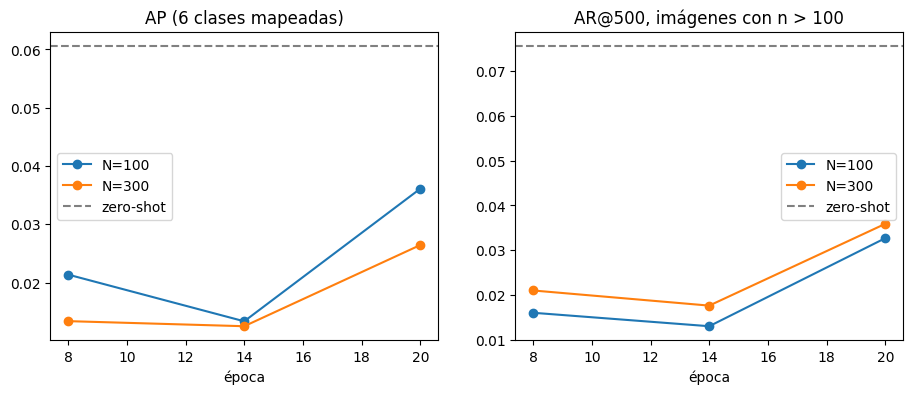

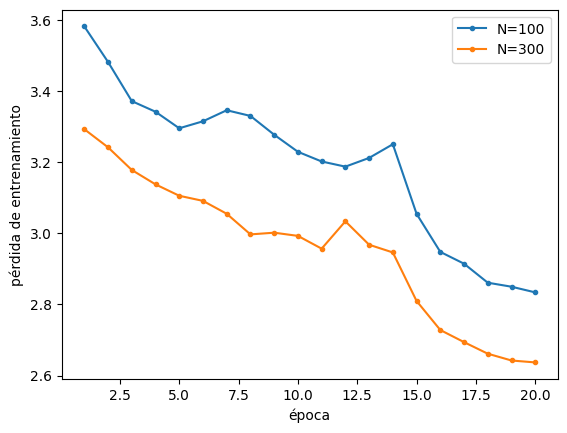

In [16]:
# Curva de aprendizaje: AP en las 6 clases comparables con el zero-shot (línea) y AR@500 en gt100
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for N in VARIANTS:
    ep = sorted(map(int, R[N]['eval']))
    ax[0].plot(ep, [R[N]['eval'][str(e)]['mapped6']['AP'] for e in ep], 'o-', label=f'N={N}')
    ax[1].plot(ep, [R[N]['eval'][str(e)]['gt100']['AR@500'] for e in ep], 'o-', label=f'N={N}')
ax[0].axhline(ZS['overall']['AP'], ls='--', c='gray', label='zero-shot'); ax[0].set_title('AP (6 clases mapeadas)')
ax[1].axhline(ZS['gt100']['AR@500'], ls='--', c='gray', label='zero-shot'); ax[1].set_title('AR@500, imágenes con n > 100')
for a in ax: a.set_xlabel('época'); a.legend()
plt.savefig(f'{OUT}/curva_aprendizaje.png', dpi=150, bbox_inches='tight'); plt.show()
for N in VARIANTS:
    plt.plot([h['epoch'] for h in R[N]['loss']], [h['loss'] for h in R[N]['loss']], 'o-', ms=3, label=f'N={N}')
plt.xlabel('época'); plt.ylabel('pérdida de entrenamiento'); plt.legend()
plt.savefig(f'{OUT}/curvas_perdida_e3.png', dpi=150, bbox_inches='tight'); plt.show()

In [17]:
# AP por clase y reparto de las detecciones (¿persiste el colapso del E2?)
pc = pd.DataFrame({f'AP N={N}': {c: v['AP'] for c, v in last[N]['por_clase'].items()} for N in VARIANTS})
for N in VARIANTS:
    d = pd.Series(last[N]['dets_por_clase']); pc[f'% dets N={N}'] = 100 * d / d.sum()
gt = pd.Series(json.load(open(VAL_JSON))['annotations']).map(lambda a: VISDRONE_CLASSES[a['category_id'] - 1]).value_counts()
pc['% cajas val'] = 100 * gt / gt.sum()
pc.to_csv(f'{OUT}/por_clase.csv'); print(pc.round(3).to_string())

                 AP N=100  AP N=300  % dets N=100  % dets N=300  % cajas val
pedestrian          0.013     0.006        22.462        34.314       22.813
people              0.006     0.004        11.263         6.445       13.211
bicycle             0.006     0.002         1.208         1.119        3.323
car                 0.117     0.085        49.695        43.943       36.298
van                 0.007     0.005         0.328         0.388        5.099
truck               0.033     0.026         1.520         1.954        1.936
tricycle            0.005     0.005         0.352         0.168        2.695
awning-tricycle     0.000     0.000         0.033         0.004        1.374
bus                 0.039     0.035         0.239         0.136        0.648
motor               0.009     0.005        12.900        11.530       12.602


## C3 · Recall por imagen frente al techo min(1, N/n) (H5) y eficiencia η = recall / techo

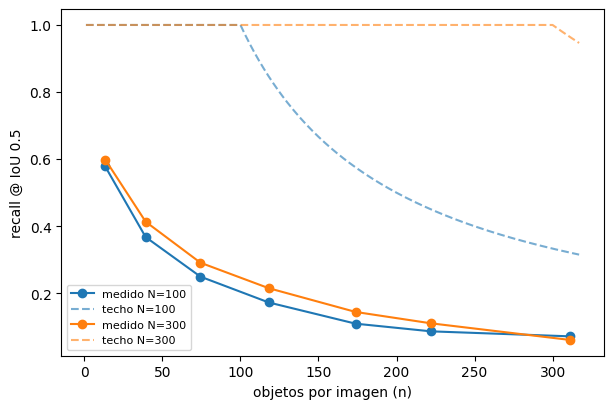

               N        n  recall  techo  imgs    eta
bin                                                  
(0, 25]      100   13.357   0.578  1.000    84  0.578
(25, 50]     100   39.282   0.368  1.000   110  0.368
(50, 100]    100   74.359   0.250  1.000   248  0.250
(100, 150]   100  118.145   0.173  0.857    76  0.202
(150, 200]   100  173.818   0.110  0.579    22  0.189
(200, 300]   100  222.200   0.087  0.452     5  0.192
(300, 1000]  100  311.333   0.072  0.321     3  0.223
(0, 25]      300   13.357   0.599  1.000    84  0.599
(25, 50]     300   39.282   0.413  1.000   110  0.413
(50, 100]    300   74.359   0.291  1.000   248  0.291
(100, 150]   300  118.145   0.215  1.000    76  0.215
(150, 200]   300  173.818   0.144  1.000    22  0.144
(200, 300]   300  222.200   0.111  1.000     5  0.111
(300, 1000]  300  311.333   0.061  0.964     3  0.063


In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5)); cnt = objects_per_image(VAL_JSON); xs = np.arange(1, max(cnt.values()) + 1)
bins = [0, 25, 50, 100, 150, 200, 300, 1000]; tabs = []
for N in VARIANTS:
    D = pd.DataFrame(last[N]['recall_img']); D = D[D.n_gt > 0]
    D['recall'] = D.tp / D.n_gt; D['techo'] = np.minimum(1, N / D.n_gt); D['bin'] = pd.cut(D.n_gt, bins)
    B = D.groupby('bin', observed=True).agg(n=('n_gt', 'mean'), recall=('recall', 'mean'), techo=('techo', 'mean'), imgs=('recall', 'size'))
    B['eta'] = B.recall / B.techo; B.insert(0, 'N', N); tabs.append(B)
    l, = ax.plot(B['n'], B['recall'], 'o-', label=f'medido N={N}')
    ax.plot(xs, np.minimum(1, N / xs), '--', color=l.get_color(), alpha=.6, label=f'techo N={N}')
ax.set_xlabel('objetos por imagen (n)'); ax.set_ylabel('recall @ IoU 0.5'); ax.legend(fontsize=8)
plt.savefig(f'{OUT}/recall_vs_techo_e3.png', dpi=150, bbox_inches='tight'); plt.show()
B = pd.concat(tabs); B.to_csv(f'{OUT}/recall_por_densidad.csv'); print(B.round(3).to_string())

## Contraste con las hipótesis (completar en el design log)
- **H4**: ¿el ajuste fino supera al zero-shot en las 6 clases y todas las clases tienen AP > 0?
- **H5**: con N = 100, ¿el recall en n > 100 se acerca al techo (η alto) o sigue lejos?
- **H6**: ¿ΔAR@500 (300 − 100) es mayor en `gt100` que en `low`?

In [28]:
import os, time, subprocess, torch

OUT2 = OUT.rstrip('/') + '_e4'          # carpeta nueva: no toca los resultados de E3
EPOCHS = 20
VARIANTS = {                            # nombre -> argumentos propios de cada corrida
    'A_drop8':  ['--N', '100', '--lr_drop', '8',  '--eval_at', '0,8,14'],
    'B_lr2e-5': ['--N', '100', '--lr_drop', '14', '--eval_at', '8,14',
                 '--lr', '2e-5', '--lr_backbone', '2e-6'],
}

def cmd(name):
    return ['python', '-u', '../src/train_e3.py', 'train', '--cache', CACHE, '--val_json', VAL_JSON,
            '--out', f'{OUT2}/{name}', '--epochs', str(EPOCHS)] + VARIANTS[name]

n_gpu = torch.cuda.device_count()
procs, gpu_of, t0 = {}, {}, time.time()
def launch(name, gpu):
    os.makedirs(f'{OUT2}/{name}', exist_ok=True)
    env = {**os.environ, 'CUDA_VISIBLE_DEVICES': str(gpu)}
    procs[name] = subprocess.Popen(cmd(name), env=env, stdout=open(f'{OUT2}/log_{name}.txt', 'w'),
                                   stderr=subprocess.STDOUT)
    gpu_of[name] = gpu

pending = list(VARIANTS)
while pending or any(p.poll() is None for p in procs.values()):
    busy = {gpu_of[n] for n in procs if procs[n].poll() is None}
    for gpu in range(max(1, n_gpu)):
        if pending and gpu not in busy:
            launch(pending.pop(0), gpu); busy.add(gpu)
    time.sleep(120)
    for name in procs:
        last = [l for l in open(f'{OUT2}/log_{name}.txt').read().splitlines() if l.startswith('[N')]
        print(f'{(time.time() - t0) / 60:5.1f} min | {name:9s} |', last[-1] if last else 'iniciando')

for name, p in procs.items():
    print(f'{name}: código de salida {p.returncode}')
    if p.returncode: print(open(f'{OUT2}/log_{name}.txt').read()[-3000:])

  2.0 min | A_drop8   | [N100] entrenables: backbone 23.23 M, resto 18.05 M
  2.0 min | B_lr2e-5  | [N100] entrenables: backbone 23.23 M, resto 18.05 M
  4.0 min | A_drop8   | [N100] época 1/20: loss 3.5825 (195.2 s)
  4.0 min | B_lr2e-5  | [N100] época 1/20: loss 3.5290 (196.4 s)
  6.0 min | A_drop8   | [N100] época 1/20: loss 3.5825 (195.2 s)
  6.0 min | B_lr2e-5  | [N100] época 1/20: loss 3.5290 (196.4 s)
  8.0 min | A_drop8   | [N100] época 2/20: loss 3.4824 (197.9 s)
  8.0 min | B_lr2e-5  | [N100] época 2/20: loss 3.2670 (199.8 s)
 10.0 min | A_drop8   | [N100] época 2/20: loss 3.4824 (197.9 s)
 10.0 min | B_lr2e-5  | [N100] época 2/20: loss 3.2670 (199.8 s)
 12.0 min | A_drop8   | [N100] época 3/20: loss 3.3723 (198.3 s)
 12.0 min | B_lr2e-5  | [N100] época 3/20: loss 3.1701 (200.2 s)
 14.0 min | A_drop8   | [N100] época 4/20: loss 3.3424 (198.7 s)
 14.0 min | B_lr2e-5  | [N100] época 4/20: loss 3.1160 (200.4 s)
 16.0 min | A_drop8   | [N100] época 4/20: loss 3.3424 (198.7 s)
 16